In [71]:
from google.colab import drive
drive.mount('/content/drive')   # a pop-up asks you to allow access to your Drive

import numpy as np
data = np.load('/content/drive/MyDrive/spike_data.npz')
print(data.files)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['t', 'raw_data']


1. Is sampling rate high enough to capture a spike?
2. What units is the raw_data in
3. any gaps in time or clipped values at amplifiers limits?
4. Spike size compared to noise
5. Refractory period/ Drift changes

In [72]:
t = data["t"]
raw = data["raw_data"]

print("t:   ", type(t), t.shape, t.dtype)
print("raw: ", type(raw), raw.shape, raw.dtype)

print("="*75)

dt = np.diff(t)          # t[1]-t[0], t[2]-t[1], ... one fewer value than t
print(dt[:5])
print(dt.min(), dt.max())
fs = 1 / np.median(dt)
print(f"Sampling frequency: {fs:.1f} Hz")

print("="*75)

print(t[:5])
print(t[-5:])  #first and last 5 time points
print("="*75)
print(raw[:10])  #first 10 voltages


t:    <class 'numpy.ndarray'> (10000,) float64
raw:  <class 'numpy.ndarray'> (10000,) float64
[0.001 0.001 0.001 0.001 0.001]
0.0009999999999994458 0.0010000000000012221
Sampling frequency: 1000.0 Hz
[0.    0.001 0.002 0.003 0.004]
[9.995 9.996 9.997 9.998 9.999]
[ 0.20712082 -0.08050916 -0.22675921  0.09332454  0.44521145 -0.06796506
  0.06324035  0.36951995  0.31029155  0.12838487]


sampling frequency 1/dt or 1000 samples per second.

In [73]:
#arrays line up?
print("Same length:", len(t) == len(raw))

#NaNs
print("NaNs in t:  ", np.isnan(t).sum(),   " infs in t:  ", np.isinf(t).sum())
print("NaNs in raw:", np.isnan(raw).sum(), " infs in raw:", np.isinf(raw).sum())

#time
dt = np.diff(t)
print("Time strictly increasing:", np.all(dt > 0))
print("Uniform sampling:", np.allclose(dt, 0.001))

#duration
print("t[-1] - t[0]:", t[-1] - t[0])
print("len(t) * dt :", len(t) * np.median(dt))
print("\n")
#raw voltage
print("Summary of the raw voltage")
print("min:   ", raw.min())
print("max:   ", raw.max())
print("mean:  ", raw.mean())
print("median:", np.median(raw))
print("std:   ", raw.std())

Same length: True
NaNs in t:   0  infs in t:   0
NaNs in raw: 0  infs in raw: 0
Time strictly increasing: True
Uniform sampling: True
t[-1] - t[0]: 9.999
len(t) * dt : 10.000000000000009


Summary of the raw voltage
min:    -1.69098912315189
max:    6.201962575902169
mean:   0.07688186859453112
median: 0.03541220827672234
std:    0.7344060361724829


1. max: (6.20 − 0.04) / 0.73~8.4 standard deviations above
2. minimum: (−1.69 − 0.04) / 0.73 ~ 2.4 standard deviations below

8 SD= suggests large positive upward signals happening!
std 0.73 mixes noise, drift, and spikes

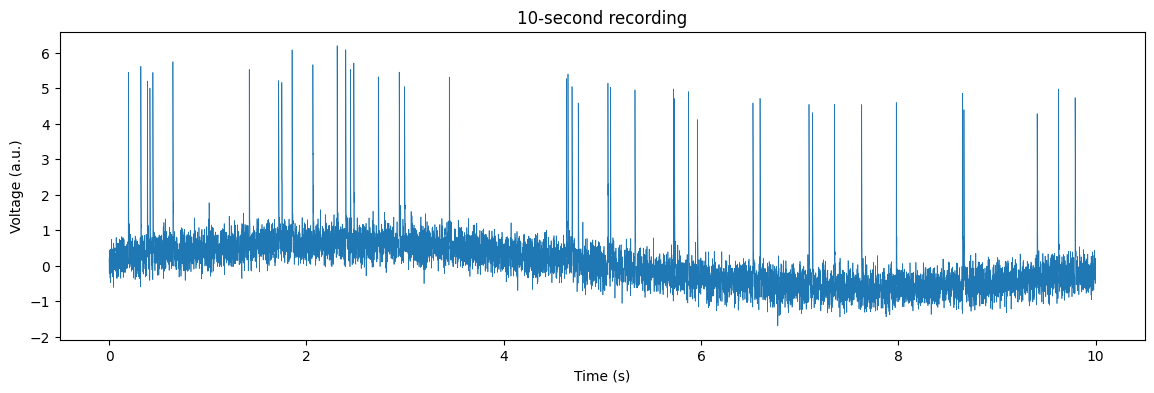

In [74]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 4))
plt.plot(t, raw, linewidth=0.5)
plt.xlabel("Time (s)")
plt.ylabel("Voltage (a.u.)")
plt.title("10-second recording")
plt.show()

I am not sure what voltage units are. The amplitudes aren't typical intracellular (mV) or extracellular (µV) scales, so I used arbitrary units.

35-45 spikes over 10 seconds is observable: 3.5-4.5 Hz, looks like clusters/bursts of spikes, not uniform. The drift only seems to move from -1au to +1au. The drift is one wave across the whole 10 seconds. Spike’s height relative to the local baseline. The noise band looks equally thick throughout.

Picking where to zoom in:
1. where baseline is its highest (1.8-3.2s)
2. baseline is lowest (6.5-8.5s)
3. where spikes look very clustered (0.5 s,  2.5,  4.5,  8.5)


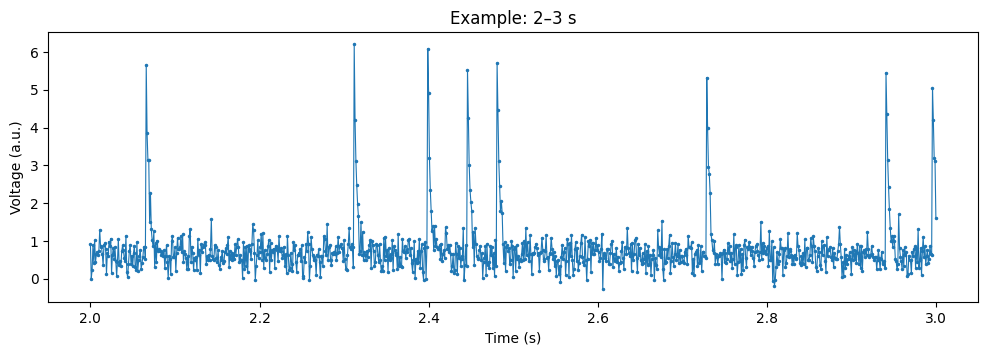

In [75]:
def plot_window(start, end, title=""):
    mask = (t >= start) & (t <= end)
    plt.figure(figsize=(12, 3.5))
    plt.plot(t[mask], raw[mask], marker=".", markersize=3, linewidth=0.8)
    plt.xlabel("Time (s)")
    plt.ylabel("Voltage (a.u.)")
    plt.title(title)
    plt.show()

plot_window(2.0, 3.0, "Example: 2–3 s")

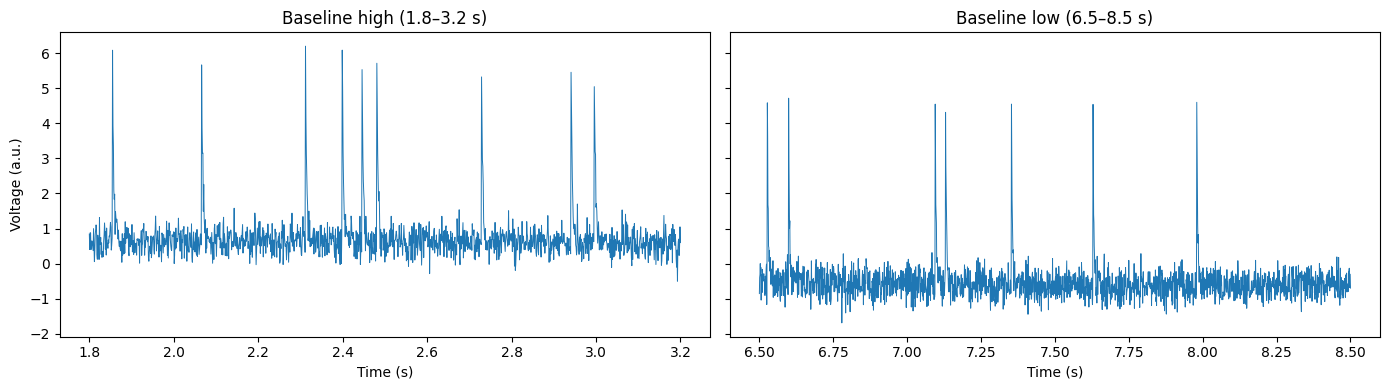

Figure A: High vs low baseline, same axis


In [76]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)

for ax, (start, end, label) in zip(axes, [(1.8, 3.2, "Baseline high"),
                                          (6.5, 8.5, "Baseline low")]):
    mask = (t >= start) & (t <= end)
    ax.plot(t[mask], raw[mask], linewidth=0.7)
    ax.set_title(f"{label} ({start}–{end} s)")
    ax.set_xlabel("Time (s)")

axes[0].set_ylabel("Voltage (a.u.)")
plt.tight_layout()
plt.show()
print("Figure A: High vs low baseline, same axis")

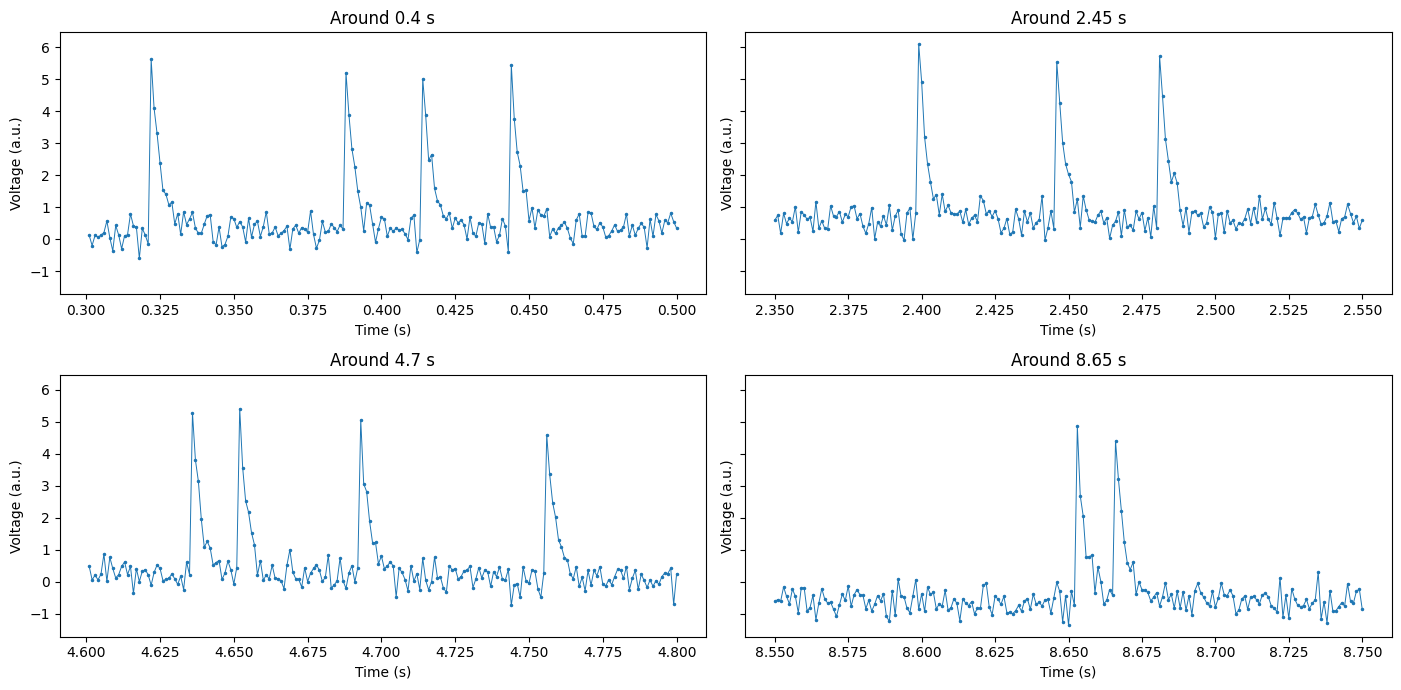

Figure B: Possible clustesr


In [77]:
centers = [0.4, 2.45, 4.7, 8.65]
half = 0.1   # ±100 ms around each center

fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharey=True)

for ax, c in zip(axes.flat, centers):
    mask = (t >= c - half) & (t <= c + half)
    ax.plot(t[mask], raw[mask], marker=".", markersize=3, linewidth=0.7)
    ax.set_title(f"Around {c} s")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Voltage (a.u.)")

plt.tight_layout()
plt.show()
print("Figure B: Possible clustesr")

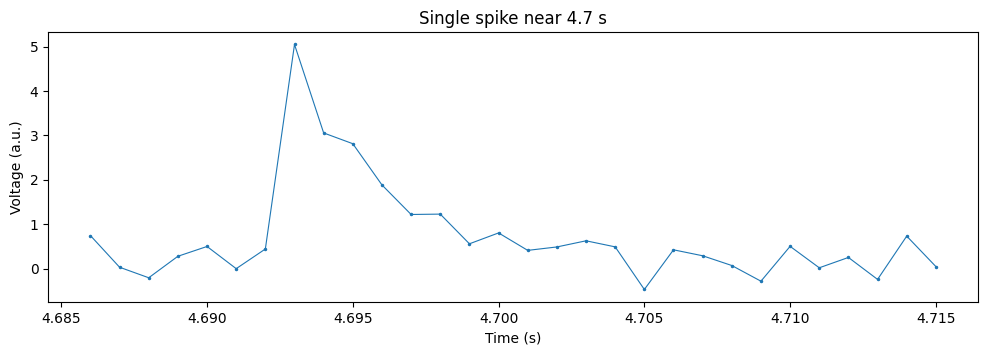

Figure C: one spike up close.


In [78]:
T=4.7
plot_window(T - 0.015, T + 0.015, f"Single spike near {T} s")
print("Figure C: one spike up close.")

## **Observations and Difficulties**

This file has two arrays, t and raw_data with each having 10,000 float64 values. A table is included of observed properties:



| Property | Result |
|---|---|
| Arrays present | `t`, `raw_data` |
| Number of samples | 10,000 (each array) |
| Array shapes | `(10000,)` for both |
| Data types | `float64` for both |
| Missing/invalid values | No NaN or inf in either array |
| Time ordering | Strictly increasing |
| Sampling interval | 0.001 s (uniform) |
| Inferred sampling frequency | 1000 Hz |
| Time range | 0.000 to 9.999 s |
| Nominal recording duration | 10 s (10,000 samples / 1000 Hz)
| Voltage units | Not specified; reported as arbitrary units (a.u.) |
| Voltage range | −1.69 to 6.20 a.u. |

The nominal duration is 10 s (10,000 samples ÷ 1000 Hz); the time vector is 0 to 9.999 s, so there are no gaps. Note, the voltage units are not stated, and the amplitudes do not really match up with typical extracellular (µV) or intracellular (mV) recordings, so I just used arbitrary units. The baseline drifts slowly, looking like a single wiave of about ±1 a.u. over the 10 s, while the noise appears equally thick throughout. The σ ~ 0.31 a.u. after drift removal, using a median-based estimate. Spikes go int he positive direction and reach up to about 5.5 a.u. above the local baseline (about 17.6σ),and are similar in height, and number roughly 35–45 by eye (about 4 Hz). Each spike rises in a single sample and decays over about 5–6 ms (Figure C).

Several difficulties could arise for detection. 1) the drift shifts spikes relative to any fixed threshold, so it must be removed first. 2)one spike spans several samples, so it must be counted only once. 3)spikes that occur close together may be hard to separate.

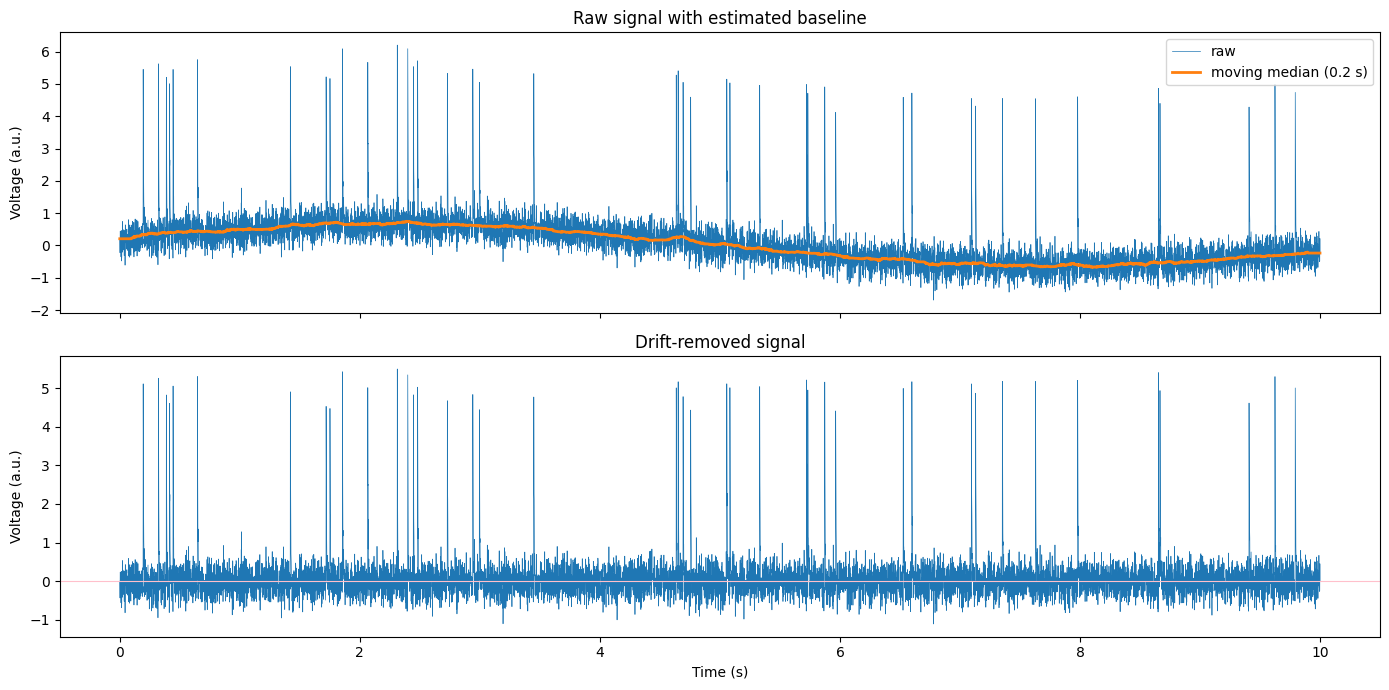

In [79]:
#A) Baseline
#Flattening the drift
from scipy.ndimage import median_filter

win_s = 0.2   # window length
win = int(round(win_s * fs)) + 1     # convert s to samples; +1 makes it odd so it has a true middle
baseline = median_filter(raw, size=win, mode="nearest")
flat = raw - baseline            # the drift-removed signal

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

axes[0].plot(t, raw, linewidth=0.5, label="raw")
axes[0].plot(t, baseline, linewidth=2, label=f"moving median ({win_s} s)")
axes[0].set_ylabel("Voltage (a.u.)")
axes[0].set_title("Raw signal with estimated baseline")
axes[0].legend()

axes[1].plot(t, flat, linewidth=0.5)
axes[1].axhline(0, color="pink", linewidth=0.8)
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Voltage (a.u.)")
axes[1].set_title("Drift-removed signal")

plt.tight_layout()
plt.show()

In [80]:
sigma_noise = np.median(np.abs(flat - np.median(flat))) / 0.6745
print(f"SD of flat signal:          {flat.std():.4f}")
print(f"MAD noise estimate (sigma): {sigma_noise:.4f}")
print(f"Earlier, MAD on raw signal: 0.6947")

print(f"Tallest spike: {flat.max():.4f}  =  {flat.max() / sigma_noise:.1f} sigma above baseline")

SD of flat signal:          0.5442
MAD noise estimate (sigma): 0.3115
Earlier, MAD on raw signal: 0.6947
Tallest spike: 5.4955  =  17.6 sigma above baseline


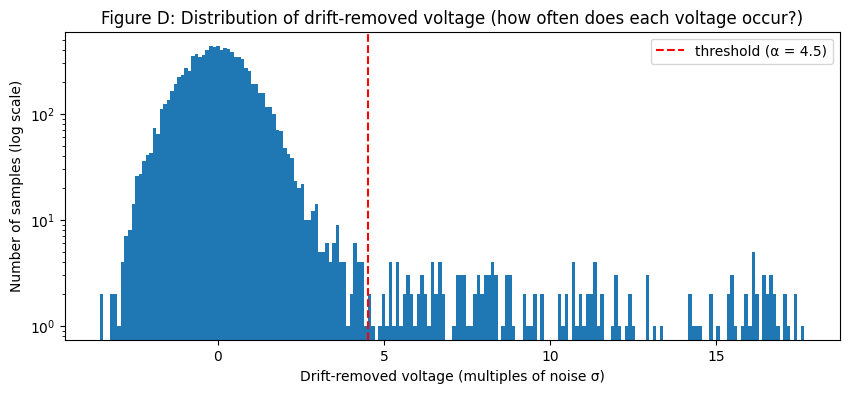

In [81]:
plt.figure(figsize=(10, 4))
plt.hist(flat / sigma_noise, bins=200)
plt.axvline(4.5, color="red", linestyle="--", label="threshold (α = 4.5)")
plt.yscale("log")
plt.xlabel("Drift-removed voltage (multiples of noise σ)")
plt.ylabel("Number of samples (log scale)")
plt.title("Figure D: Distribution of drift-removed voltage (how often does each voltage occur?)")
plt.legend()
plt.show()

Histogram of drift removed voltage in units of the noise σ. Bell shaped part centered at zero represents the noise, and the scattered bars to the right are my spike samples; all positive direction. Threshold 4.5 sits above the noise and below spike peaks.

## **Detection Specification**


1. https://www.sciencedirect.com/science/article/pii/S0165027026000804#sec0010

2. https://direct.mit.edu/neco/article/16/8/1661/6903/Unsupervised-Spike-Detection-and-Sorting-with

MAD estimator comes from Quiroga et al., 2004

1. Remove slow drift
2. Measure how big noise is
3. Draw the line of some multiple of the noise size
4. Count spike if above that line
5. Firing Rate= spikes /10 s

1. What makes a sample/group of samples a spike?
- A spike would be an event in which the signal rises more than a determined multiple of the noise standard deviation above the local baseline. Also, spikes in this recording are going in the positive direction. A single spike could have several consecutive samples above this threshold, as seen on **Figure C** which has about 5-6 sampoles as one event. So therefor a run of consecutive, positive,  above the threshold samples could count as one event.

2. How did I chose the parameters?
- Baseline window (0.2s)
    1. A moving median subtracted from the signal
    2. I will chose a window length longer than a spike (.006 s), shorter than the drift (10 s)
    3. The median will therefor ignore the few spike samples in the window, and the draft will be nearly flat within it.
- Noise size (σ=0.31)
    1. SD of noise, using the drift removed signal
    2. Using this data, the ordinary SD of the drift-removed signal is 0.54, about 75% large than the MAD estimate (0.31), because the spikes inflate it.
    3. MED/MAD estimator: median(|x − median(x)|) / 0.6745. MAD on raw signal is 0.69, more than twice as large because the drift inflates it.
     
- Multiple (α= not sure yet)
    1. threshold is α × σ above the baseline.
    2. needs to be high enough that pure noise will not cross, but low that a real spike will cross
    3. Gaussian noise, the expected number of noise samples crossing 5σ in 10,000 samples is about 0.003, so false detections from noise should be zero.

3. How will I count an even only once:
- I will count upward threshold crossings, not samples above it, because one spike keeps about 4 or 5 consecutive samples above the line (Figure C) and counting samples would count each spike several times. In addition from looking at Figure C, I can tell the spike’s tail decays for about 5ms. So after each detected spike I will ignore any new crossings for a dead time of 5 ms, because noise on the tail could otherwise push it back above the threshold and cause a second inaccurate crossing.

4. How will I handle edge cases:
- For the drift: subtracting the 0.2 s moving median before thresholding. So the threshold is relative to the local baseline rather than just zero. For closer spikes: two real spikes less than 5 ms apart would be merged and counted as one, which would cause undercounting; the possible pair near 8.65s in Figure B is a case to check. And, spikes only slightly above 5σ may be missed, or caught only sometimes depending on the noise. The α comparison in the next question would test how much this matters.

5. How will I test this detection method:
- I will mark the detected spikes on the full recording and on the zoomed plots on Figures A to C and check by eye that every obvious spike has a mark and that no marks fall on plain noise. I counted about 35–45 spikes by eye (around 4 Hz). If the detector’s count is far outside this range, something is likely wrong with the method

- I could repeat the count with α = 4, 5 and 6, and with baseline windows of 0.1 s and 0.5 s. If the count changes only a little, the result is robust; if it changes a lot, the result depends on the parameter choice.

Notes: 1 neuron or several ? PCA or SVD?
